# SCA VSET IGSF RP55

**Summary:**  This script follows the basic flow of analytical steps in SCA6.0, using the IGSF vset domain (55% representative proteome seqs). The analysis consists of five steps, which directly follow from the accompanying publication (Rivoire et al, "An Evolution-Based Functional Decomposition of Natural Proteins"):

**1)  Alignment processing and composition.**
We begin by analyzing the composition of the mulitple sequence alignment: what is the number of effective sequences, and how are the sequences structured into families? 

**2) First-order statistics: position-specific conservation.**
Next, we examine overall positional conservation for the sequence alignment. This shows the expected result, that a handful of positions are strongly conserved. 

**3) Second-order statistics: conserved correlations.**
Plots of the SCA matrix ($\tilde{C_{ij}}$), the associated eigenvectors and eigenspectrum, and the corresponding independent components (IC). We choose the number of significant eigenmodes, $k^* = 4$,  by comparison of the eigenspectrum of $\tilde{C_{ij}}$ to that for a collection of 10 randomized alignments.  

**4) Sector decomposition.**
Sector definition based on the top $k^*$ ICs.  We begin by fitting the top $k^*$ statistically significant ICs to a t-distribution, and then identify the amino acid positions contributing to the top five percent of the corresponding cumulative density function. We then construct a sub-matrix of $\tilde{C_{ij}}$ that contains only the selected top-scoring positions for the $k^*$ ICs, ordered by their degree of contribution to each IC. This plot is used to choose sector assignments.


Prior to running this tutorial, the core calculation scripts must be executed from the command line as follows:

    >> scaProcessMSA -a ../data/PF00071_rd2.an -b ../data/ -s 5P21 -c A -f 'Homo sapiens' -t -n
    >> scaCore -i ../output/PF00071_rd2.db
    >> scaSectorID -i ../output/PF00071_rd2.db

In [1]:
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import copy
import scipy.cluster.hierarchy as sch
from scipy.stats import scoreatpercentile 
import matplotlib.image as mpimg
from IPython.display import display
from IPython.display import Image
from Bio.Seq import Seq
from Bio import motifs
import colorsys
from pysca import scaTools as sca
# import mpld3
import pickle as pickle
from optparse import OptionParser

%matplotlib inline

if not os.path.exists('../output/'):
    os.makedirs('../output/')  

To begin, we read in the results of the above three scripts (scaProcessMSA, scaCore and scaSectorID), stored as three dictionaries in the database PF00071_full.db.  To see what variables are stored in each dictionary, use the command dictionary.keys( ), e.g.:

    >>> print Dseq.keys()

In [1]:
db = pickle.load(open('../output/vset_rp55.db','rb'))
Dseq = db['sequence']  #the results of scaProcessMSA
Dsca = db['sca']       #the results of scaCore
Dsect = db['sector']   #the results of scaSectorID

NameError: name 'pickle' is not defined

### I. Alignment processing and composition

First, we print out a few statistics describing the alignment:

In [3]:
print("After processing, the alignment size is %i sequences and %i positions" % \
      (Dseq['Nseq'], Dseq['Npos']))
print("With sequence weights, there are %i effective sequences" % (Dseq['effseqs']))

After processing, the alignment size is 15326 sequences and 84 positions
With sequence weights, there are 6325 effective sequences


To examine alignment composition, we plot a histogram of all pairwise sequence identities *(left panel)* and a global view of the sequence similarity matrix (defined by $S\equiv \frac{1}{L}XX^\top$) *(right panel)*.  

In [3]:
# List all elements above the diagonal (i<j):
listS = [Dsca['simMat'][i,j] for i in range(Dsca['simMat'].shape[0]) \
         for j in range(i+1, Dsca['simMat'].shape[1])]

# Cluster the sequence similarity matrix
Z = sch.linkage(Dsca['simMat'],method = 'complete', metric = 'cityblock')
R = sch.dendrogram(Z,no_plot = True)
ind = R['leaves']

# Plotting
plt.rcParams['figure.figsize'] = 9, 4 
plt.subplot(121)
plt.hist(listS, int(round(Dseq['Npos']/2)))
plt.xlabel('Pairwise sequence identities', fontsize=14)
plt.ylabel('Number', fontsize=14)
plt.subplot(122)
plt.imshow(Dsca['simMat'][np.ix_(ind,ind)], vmin=0, vmax=1); plt.colorbar();

NameError: name 'Dsca' is not defined

### II. <u> First-order statistics: position-specific conservation.  <u/>

Plot the position-specific conservation values for each g-protein position. $D_i$ is calculated according to equation S4 (supplemental information).

In [4]:
sca.chooseKpos(Dsect['Lsca'], Dsca['Lrand'])

4

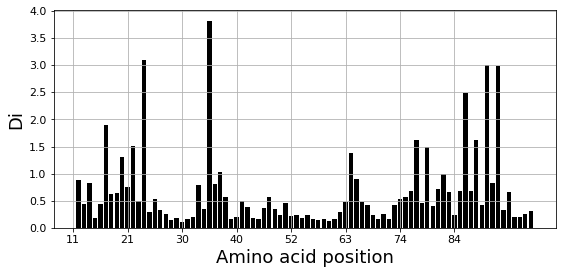

In [16]:
fig, axs = plt.subplots(1,1, figsize=(9,4))
xvals = [i+1 for i in range(len(Dsca['Di']))]
xticks = [0,10,20,30,40,50,60,70]
plt.bar(xvals,Dsca['Di'], color='k')
plt.tick_params(labelsize=11); plt.grid()
axs.set_xticks(xticks);
labels = [Dseq['ats'][k] for k in xticks]
axs.set_xticklabels(labels);
plt.xlabel('Amino acid position', fontsize=18); plt.ylabel('Di', fontsize=18);

### III. <u>Second-order statistics: conserved correlations.<u/>

Plot the SCA correlation matrix ( $\tilde{C_{ij}}$ ) computed according to Equations 4+5

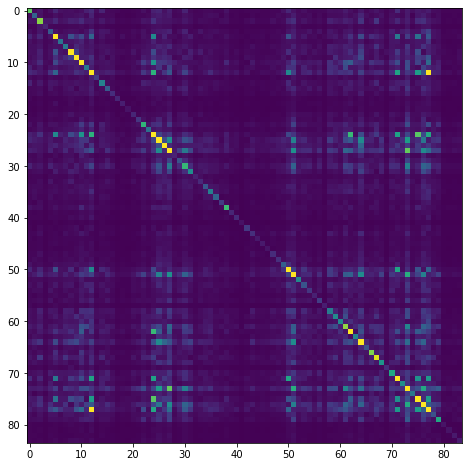

In [7]:
plt.rcParams['figure.figsize'] = 13, 8
plt.imshow(Dsca['Csca'], vmin=0, vmax=1.4,interpolation='none',\
           aspect='equal')

Plot the eigenspectrum of (1) the SCA positional coevolution matrix ($\tilde{C_{ij}}$) *(black bars)* and (2) 10 trials of matrix randomization for comparison. This graph is used to choose the number of significant eigenmodes ($k^* = 4$).

Number of eigenmodes to keep is 4


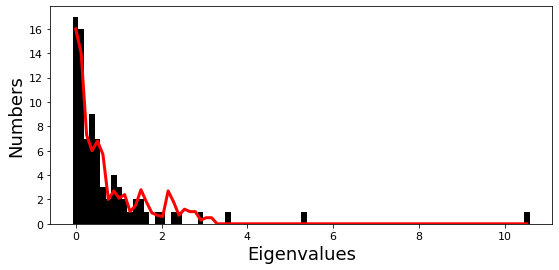

In [8]:
plt.rcParams['figure.figsize'] = 9, 4 
hist0, bins = np.histogram(Dsca['Lrand'].flatten(), bins=Dseq['Npos'], \
                           range=(0,Dsect['Lsca'].max()))
hist1, bins = np.histogram(Dsect['Lsca'], bins=Dseq['Npos'], \
                           range=(0,Dsect['Lsca'].max()))
plt.bar(bins[:-1], hist1, np.diff(bins),color='k')
plt.plot(bins[:-1], hist0/Dsca['Ntrials'], 'r', linewidth=3)
plt.tick_params(labelsize=11)
plt.xlabel('Eigenvalues', fontsize=18); plt.ylabel('Numbers', fontsize=18);
print('Number of eigenmodes to keep is %i' %(Dsect['kpos']))
#mpld3.display()

Plot the top significant eigenmodes *(top row)* and associated independent components *(bottom row)*. The ICs are an optimally independent representation of the four different residue groups.

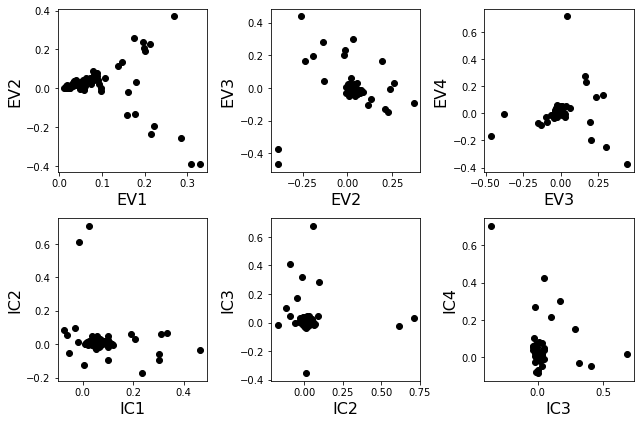

In [9]:
plt.rcParams['figure.figsize'] = 9, 6
EVs = Dsect['Vsca']
ICs = Dsect['Vpica']
pairs = [ [x,x+1] for x in range(Dsect['kpos']-1)]
ncols = len(pairs)
for k,[k1,k2] in enumerate(pairs):
    plt.subplot(2,ncols,k+1)
    plt.plot(EVs[:,k1], EVs[:,k2], 'ok')
    plt.xlabel("EV%i"%(k1+1), fontsize=16)
    plt.ylabel("EV%i"%(k2+1), fontsize=16)
    plt.subplot(2,ncols,k+1+ncols)
    plt.plot(ICs[:,k1], ICs[:,k2], 'ok')
    plt.xlabel("IC%i"%(k1+1), fontsize=16)
    plt.ylabel("IC%i"%(k2+1), fontsize=16)
plt.tight_layout()

### IV. <u> Sector decomposition. <u/>

To define the positions with significant contributions to each of the independent components (ICs), we make a empirical fit for each IC to the t-distribution and select positions with greater than a specified cutoff on the CDF.  We choose $p=0.95$ as our cutoff.  Note that since some positions might contribute significantly to more than one IC (an indication of non-independence of ICs), we  apply a simple algorithm to assign such positions to one IC.  Specifically, we assign positions to the IC with which it has the greatest degree of co-evolution.<br/>

The data indicate generally good fits for the top five ICs (also shown in supplemental figure S2), and we return the positions contributing to each IC in a format suitable for cut and paste into PyMol.  

['35', '37', '40', '64', '75', '78', '87', '90']
IC 1 is composed of 8 positions:
35+37+40+64+75+78+87+90

['23', '89', '91']
IC 2 is composed of 3 positions:
23+89+91

['21', '34', '76']
IC 3 is composed of 3 positions:
21+34+76

['16', '19', '63', '85']
IC 4 is composed of 4 positions:
16+19+63+85



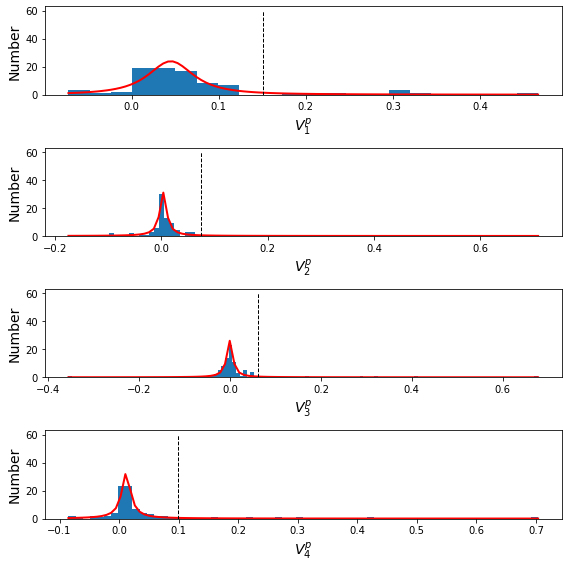

In [10]:
plt.rcParams['figure.figsize'] = 8, 8 

Vpica = Dsect['Vpica']
for k in range(Dsect['kpos']):
    iqr = scoreatpercentile(Vpica[:,k],75) - scoreatpercentile(Vpica[:,k],25)
    binwidth=2*iqr*(len(Vpica)**(-0.33))
    nbins=int(round((max(Vpica[:,k])-min(Vpica[:,k]))/binwidth))
    plt.subplot(Dsect['kpos'],1,k+1)
    h_params = plt.hist(Vpica[:,k], nbins)
    x_dist = np.linspace(min(h_params[1]), max(h_params[1]), num=100)
    plt.plot(x_dist,Dsect['scaled_pd'][k],'r',linewidth = 2)  
    plt.plot([Dsect['cutoff'][k],Dsect['cutoff'][k]], [0,60], 'k--',linewidth = 1)
    plt.xlabel(r'$V^p_{%i}$'%(k+1), fontsize=14)
    plt.ylabel('Number', fontsize=14)
plt.tight_layout()    

for n,ipos in enumerate(Dsect['ics']):
    sort_ipos = sorted(ipos.items)
    ats_ipos = ([Dseq['ats'][s] for s in sort_ipos])
    print(ats_ipos)
    ic_pymol = ('+'.join(map(str, ats_ipos) ))
    print('IC %i is composed of %i positions:' % (n+1,len(ats_ipos)))
    print(ic_pymol + "\n")
        

To define protein sectors, we examine the structure of the SCA positional correlation matrix with positions contributing to the top  independent components (ICs) ordered by weight (*left panel*).  This provides a basis to determine/interpret which ICs are truly statistically independent (defining an independent sector) and which represent hierarchical breakdowns of one sector. In this case, the data suggest that ICs 1, 2, and 3 have strong inter-IC correlations and should be considered a single sector, and IC4 shows little corrleation with other ICs, implying a distinct sector (see the dendrogram that follows).  In the *right panel* the ICs are re-ordered to reflect this decomposition. 

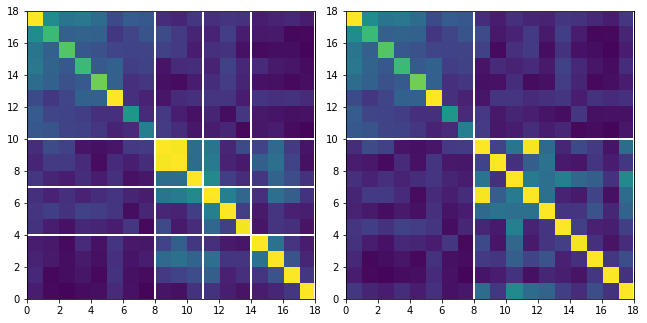

In [13]:
#plot the SCA positional correlation matrix, ordered by contribution to the top ICs
plt.rcParams['figure.figsize'] = 9, 9 
plt.subplot(121)
plt.imshow(Dsca['Csca'][np.ix_(Dsect['sortedpos'], Dsect['sortedpos'])], \
           vmin=0, vmax=2.2,interpolation='none',\
           aspect='equal',extent=[0,sum(Dsect['icsize']),\
                                  0,sum(Dsect['icsize'])])
line_index=0
for i in range(Dsect['kpos']):
    plt.plot([line_index+Dsect['icsize'][i],line_index+Dsect['icsize'][i]],\
             [0,sum(Dsect['icsize'])],'w', linewidth = 2)
    plt.plot([0,sum(Dsect['icsize'])],[sum(Dsect['icsize'])-\
            line_index,sum(Dsect['icsize'])-line_index],'w', linewidth = 2)
    line_index += Dsect['icsize'][i] 

#define the new sector groupings - 3 total
sec_groups = ([0],[1,2,3])
sectors = list()
c = [0.66, 0,0.2,0.4]
for n,k in enumerate(sec_groups):
    s = sca.Unit()
    all_items = list()
    all_Vp = list()
    for i in k: 
        all_items = all_items+Dsect['ics'][i].items
        all_Vp = all_Vp+list(Dsect['ics'][i].vect)
    svals = np.argsort(all_Vp)    
    s.items = [all_items[i] for i in svals]
    s.col = c[n]
    sectors.append(s)

#plot the re-ordered matrix
plt.subplot(122)
line_index=0
sortpos = list()
for s in sectors:
    sortpos.extend(s.items)
plt.imshow(Dsca['Csca'][np.ix_(sortpos, sortpos)], vmin=0, vmax=2.2,\
           interpolation='none',aspect='equal',\
           extent=[0,len(sortpos),0,len(sortpos)])
for s in sectors:
    plt.plot([line_index+len(s.items),line_index+len(s.items)],\
             [0,len(sortpos)],'w', linewidth = 2)
    plt.plot([0,sum(Dsect['icsize'])],[len(sortpos)-line_index,\
                    len(sortpos)-line_index],'w', linewidth = 2)
    line_index += len(s.items)
plt.tight_layout()

Print the sector positions, in a format suitable for pyMol, and create a pyMol session (in the output directory) with the sectors (and decomposition into independent components) as seperate objects.

In [14]:
for i,k in enumerate(sectors):
    sort_ipos = sorted(k.items)
    ats_ipos = ([Dseq['ats'][s] for s in sort_ipos])
    ic_pymol = ('+'.join(ats_ipos))
    print('Sector %i is composed of %i positions:' % (i+1,len(ats_ipos)))
    print(ic_pymol + "\n")
sca.writePymol('5P21', sectors, Dsect['ics'], Dseq['ats'], \
               '../output/PF00071.pml','A', '../Inputs/', 0)  

Sector 1 is composed of 8 positions:
35+37+40+64+75+78+87+90

Sector 2 is composed of 10 positions:
16+19+21+23+34+63+76+85+89+91

